# 03. Job Security & Layoff Risks Analysis (1999–2024)

This notebook processes indicators related to employment stability and economic uncertainty using FSD survey datasets. It extracts and analyzes:
1. **Furlough Risk (`K22_1`)**: Likelihood of temporary layoffs / lomautus.
2. **Dismissal Risk (`K22_2`)**: Likelihood of permanent job loss / irtisanomisriski.
3. **Job Security Agreement (`K21C_6`)**: Agreement with statements regarding long-term job retention.

In [1]:
# ==========================================
# 1. IMPORTS & CONFIGURATION
# ==========================================

import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Dictionary to map archive dataset codes to real years
fsd_year_mapping = {
    '3049': 2014,
    '3131': 2015,
    '3220': 2016,
    '3481': 2017,
    '3482': 2018,
    '3493': 2019,
    '3645': 2020,
    '3727': 2021,
    '3784': 2022,
    '3914': 2023,
    '4011': 2024,
}


# Function to find year from filename using the mapping dictionary
def get_year(filename):
  for code, year in fsd_year_mapping.items():
    if code in filename:
      return year
  return None


# Safe function to load CSV files with fallback separators and validation
def load_raw_csv(filepath):
  # Try both semicolon and comma separators
  for sep in [';', ',']:
    try:
      df = pd.read_csv(
          filepath, sep=sep, low_memory=False, encoding='utf-8-sig'
      )
      # Ensure it actually parsed multiple columns (not just a single big string column)
      if len(df.columns) > 1:
        return df
    except:
      continue
  return None

In [2]:
# ==========================================
# 2. DATA EXTRACTION
# ==========================================

job_security_data = []

# Find all CSV files inside the 'data' folder
all_csvs = glob.glob(os.path.join('data', 'daF*.csv'))

for file_path in all_csvs:
    filename = os.path.basename(file_path)
    year = get_year(filename)

    if year is None:
        continue

    # Load CSV safely
    df = load_raw_csv(file_path)
    if df is None:
        continue

    cols = {c.lower(): c for c in df.columns}

    # 1. Standard Risk Indicators (2014-2024)
    variables = [
        ('k22_2', 'Dismissal Risk'),
        ('k22_1', 'Furlough Risk'),
    ]

    # 2. Dynamic choice for Job Security variable depending on the year
    # K21C_6 is used up to 2020, K23 is used from 2021 onwards
    if year <= 2020:
        variables.append(('k21c_6', 'Job Security'))
    else:
        variables.append(('k23', 'Job Security'))

    # Loop through each variable and calculate mean
    for var_key, measure_name in variables:
        col_name = cols.get(var_key)

        if col_name and col_name in df.columns:
            s = pd.to_numeric(df[col_name], errors='coerce')
            valid = s[(s >= 1) & (s <= 4)]

            if len(valid) > 0:
                job_security_data.append({
                    'Year': year,
                    'File': filename,
                    'Measure': measure_name,
                    'N': len(valid),
                    'Mean': round(valid.mean(), 3),
                })

print(f'Processed {len(job_security_data)} records for job security!')

Processed 33 records for job security!


In [3]:
# ==========================================
# 3. DISPLAY & EXPORT RESULTS
# ==========================================

# Check if we have data in our list
if len(job_security_data) > 0:

  # Convert list of dictionaries into a DataFrame
  df_security = pd.DataFrame(job_security_data)

  # Sort table by Year and Measure
  df_security = df_security.sort_values(['Year', 'Measure'])

  # Print table without row numbers
  print(df_security.to_string(index=False))

  # Save results to a new CSV file
  df_security.to_csv('job_security_2014_2024.csv', index=False)
  print('Done! Job security file saved successfully.')

else:
  print('Error: No matching files processed.')

 Year            File        Measure    N  Mean
 2014 daF3049_fin.csv Dismissal Risk 1684 3.443
 2014 daF3049_fin.csv  Furlough Risk 1673 3.261
 2014 daF3049_fin.csv   Job Security 1667 2.043
 2015 daF3131_eng.csv Dismissal Risk 1693 3.417
 2015 daF3131_eng.csv  Furlough Risk 1698 3.287
 2015 daF3131_eng.csv   Job Security 1706 2.113
 2016 daF3220_eng.csv Dismissal Risk 1593 3.424
 2016 daF3220_eng.csv  Furlough Risk 1587 3.374
 2016 daF3220_eng.csv   Job Security 1597 2.002
 2017 daF3481_eng.csv Dismissal Risk 1649 3.502
 2017 daF3481_eng.csv  Furlough Risk 1649 3.458
 2017 daF3481_eng.csv   Job Security 1654 1.949
 2018 daF3482_eng.csv Dismissal Risk 1612 3.545
 2018 daF3482_eng.csv  Furlough Risk 1611 3.533
 2018 daF3482_eng.csv   Job Security 1613 1.881
 2019 daF3493_eng.csv Dismissal Risk 1520 3.560
 2019 daF3493_eng.csv  Furlough Risk 1509 3.482
 2019 daF3493_eng.csv   Job Security 1528 1.822
 2020 daF3645_eng.csv Dismissal Risk 1604 3.489
 2020 daF3645_eng.csv  Furlough Risk 160

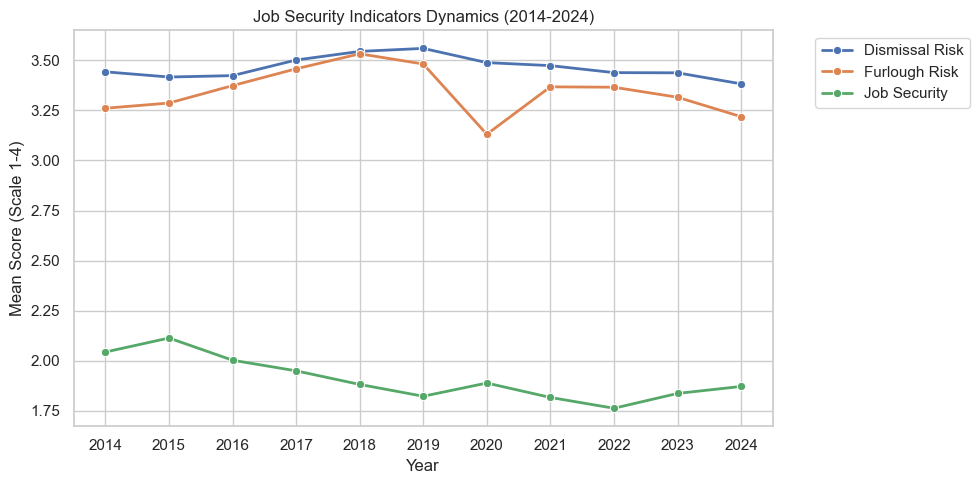

In [4]:
# ==========================================
# 4. PLOT: Job Security Dynamics
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Load data from CSV file
df_plot = pd.read_csv('job_security_2014_2024.csv')

# Set visual style and figure size
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 5))

# Plot lines for each job security measure
sns.lineplot(
    data=df_plot,
    x='Year',
    y='Mean',
    hue='Measure',
    marker='o',
    linewidth=2,
)

# Add titles and labels
plt.title('Job Security Indicators Dynamics (2014-2024)')
plt.xlabel('Year')
plt.ylabel('Mean Score (Scale 1-4)')

# --- FIX: Force X-axis to show all years from 2014 to 2024 ---
plt.xticks(range(2014, 2025))

# Show grid and legend
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout and save
plt.tight_layout()
plt.savefig('job_security_trend_2014_2024.png', dpi=300)
plt.show()